In [2]:
import sys, os

def find_order_analyzer_parent(start=None):
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, "features")) and os.path.isdir(os.path.join(current, "OCTA_toolbox-master")):
            return os.path.abspath(os.path.join(current, os.pardir))
        if os.path.isdir(os.path.join(current, "order_analyzer")) and os.path.isdir(os.path.join(current, "order_analyzer", "features")):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            return None
        current = parent

project_parent = find_order_analyzer_parent()
if project_parent is None:
    raise RuntimeError(f"Cannot find order_analyzer parent from cwd={os.getcwd()}")
if project_parent not in sys.path:
    sys.path.insert(0, project_parent)
print("added path:", project_parent)
print("cwd:", os.getcwd())
print("sys.path[0:4] =", sys.path[:4])

import importlib
import order_analyzer.features.analyzer as _m
importlib.reload(_m)
from order_analyzer import OrderAnalyzer

added path: d:\PROJECTS\understandOtherPackage
cwd: d:\PROJECTS\understandOtherPackage\order_analyzer\test
sys.path[0:4] = ['d:\\PROJECTS\\understandOtherPackage', 'd:\\PROJECTS\\understandOtherPackage\\order_analyzer\\.pixi\\envs\\default\\python312.zip', 'd:\\PROJECTS\\understandOtherPackage\\order_analyzer\\.pixi\\envs\\default\\DLLs', 'd:\\PROJECTS\\understandOtherPackage\\order_analyzer\\.pixi\\envs\\default\\Lib']


In [2]:
# 3x3 全矩形，ideal 和 actual 完全一致
grid = [
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
]

In [3]:
import sys
for key in list(sys.modules):
    if "order_analyzer" in key:
        del sys.modules[key]
from order_analyzer import OrderAnalyzer

In [4]:
result = OrderAnalyzer(
    actual_matrix=grid,
    ideal_matrix=grid,
    cell_size=(40, 80)          # 宽40 高80 → 长方形
).report(features=("shapes", "custom_attr"))
print(result)

{'n_rows': 3, 'n_cols': 3, 'n_cells': 9, 'features': ['shapes', 'custom_attr'], 'deviants': 0, 'order': 1.0}


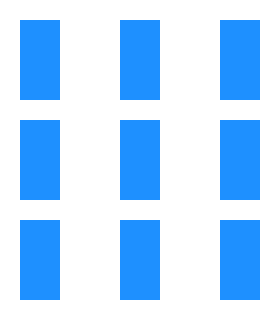

In [5]:
analyzer = OrderAnalyzer(actual_matrix=grid, ideal_matrix=grid, cell_size=(40, 80))
analyzer._prepare()
analyzer._stim.Show()

{'n_rows': 3, 'n_cols': 3, 'n_cells': 9, 'features': ['orientations'], 'schema': {'version': 'v1', 'required': ['shape'], 'defaults': {'shape': 'rect', 'attr': '', 'orientation': 0.0, 'role': '', 'group': 'global'}}, 'semantic': {'role_grid': [['table', 'table', 'table'], ['table', 'table', 'table'], ['table', 'table', 'table']], 'group_grid': [['global', 'global', 'global'], ['global', 'global', 'global'], ['global', 'global', 'global']], 'role_counts': {'table': 9}, 'group_counts': {'global': 9}}, 'deviants': 2, 'order': 0.7778, 'deviance_by_feature': {'orientations': {'count': 2, 'ratio': 0.2222}}, 'deviance_matrix': [[0, 1, 1], [0, 0, 0], [0, 0, 0]], 'deviance_cells': [{'row': 0, 'col': 1}, {'row': 0, 'col': 2}], 'scores': {'base_order': 0.7778, 'intra': 0.9045, 'inter': 1.0, 'rel': None, 'total': 0.8804}, 'details': {'intra_groups': {'global': 0.9045}, 'inter': {'orientation_alignment': 1.0, 'phase_alignment': 1.0}, 'relation': {'rel': None, 'subscores': {'distance': None, 'bearin

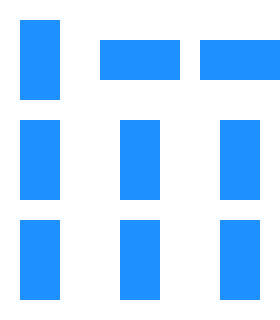

In [4]:
import sys
for key in list(sys.modules):
    if "order_analyzer" in key:
        del sys.modules[key]
from order_analyzer import OrderAnalyzer

ideal = [
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
]

# 第一行索引1、2的格子转90度
actual = [
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A", "orientation": 90}, {"shape": "rect", "attr": "A", "orientation": 90}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
]

result = OrderAnalyzer(actual_matrix=actual, ideal_matrix=ideal, cell_size=(40, 80)).report(features=("orientations",))
print(result)

analyzer3 = OrderAnalyzer(actual_matrix=actual, ideal_matrix=ideal, cell_size=(40, 80))
analyzer3._prepare()
analyzer3._stim.Show()

In [5]:
# 新 analyzer 现地验证：复现 3x3 旋转偏差案例并查看新输出字段
import importlib
import order_analyzer.features.analyzer as _m
importlib.reload(_m)
from order_analyzer import OrderAnalyzer

ideal = [
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
]

actual = [
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A", "orientation": 90}, {"shape": "rect", "attr": "A", "orientation": 90}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
    [{"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}, {"shape": "rect", "attr": "A"}],
]

report = OrderAnalyzer(
    actual_matrix=actual,
    ideal_matrix=ideal,
    cell_size=(40, 80),
).report(features=("orientations",))

print("order:", report["order"])
print("deviants:", report["deviants"], "expected=2")
print("deviance_by_feature:", report["deviance_by_feature"])
print("deviance_cells:", report["deviance_cells"])
print("deviance_matrix:")
for row in report["deviance_matrix"]:
    print(row)

print("scores:", report["scores"])
print("semantic role_counts:", report["semantic"]["role_counts"])

order: 0.7778
deviants: 2 expected=2
deviance_by_feature: {'orientations': {'count': 2, 'ratio': 0.2222}}
deviance_cells: [{'row': 0, 'col': 1}, {'row': 0, 'col': 2}]
deviance_matrix:
[0, 1, 1]
[0, 0, 0]
[0, 0, 0]
scores: {'base_order': 0.7778, 'intra': 0.9045, 'inter': 1.0, 'rel': None, 'total': 0.8804}
semantic role_counts: {'table': 9}


### Ideal (全0度)

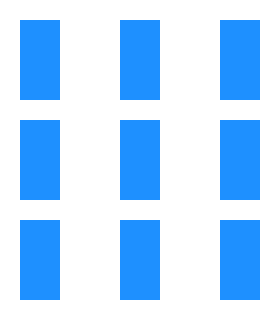

### Actual (前两格旋转90度)

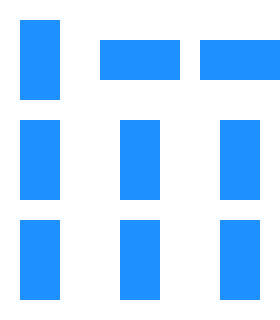

In [6]:
# 可视化对比：ideal vs actual
from IPython.display import display, Markdown

display(Markdown("### Ideal (全0度)"))
ideal_view = OrderAnalyzer(actual_matrix=ideal, ideal_matrix=ideal, cell_size=(40, 80))
ideal_view._prepare()
ideal_view._stim.Show()

display(Markdown("### Actual (前两格旋转90度)"))
actual_view = OrderAnalyzer(actual_matrix=actual, ideal_matrix=ideal, cell_size=(40, 80))
actual_view._prepare()
actual_view._stim.Show()

Table class order: 0.7778
Table class deviants: 2
Table class deviance_cells: [{'row': 0, 'col': 1}, {'row': 0, 'col': 2}]


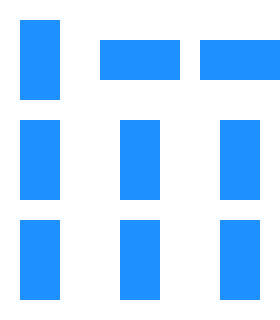

In [9]:
# Table 类重演示：不再手写 dict，而是用领域对象输入
import importlib
import order_analyzer.features.schema as _s
import order_analyzer.features.entities as _e
import order_analyzer.features.analyzer as _m
importlib.reload(_s)
importlib.reload(_e)
importlib.reload(_m)
from order_analyzer import OrderAnalyzer
from order_analyzer.features.entities import Table

ideal_table = [
    [Table(attr="A"), Table(attr="A"), Table(attr="A")],
    [Table(attr="A"), Table(attr="A"), Table(attr="A")],
    [Table(attr="A"), Table(attr="A"), Table(attr="A")],
]

actual_table = [
    [Table(attr="A"), Table(attr="A", orientation=90), Table(attr="A", orientation=90)],
    [Table(attr="A"), Table(attr="A"), Table(attr="A")],
    [Table(attr="A"), Table(attr="A"), Table(attr="A")],
]

table_report = OrderAnalyzer(
    actual_matrix=actual_table,
    ideal_matrix=ideal_table,
    cell_size=(40, 80),
).report(features=("orientations",))

print("Table class order:", table_report["order"])
print("Table class deviants:", table_report["deviants"])
print("Table class deviance_cells:", table_report["deviance_cells"])

table_view = OrderAnalyzer(actual_matrix=actual_table, ideal_matrix=ideal_table, cell_size=(40, 80))
table_view._prepare()
table_view._stim.Show()

shape order: 0.75
shape deviants: 1
shape deviance_cells: [{'row': 0, 'col': 1}]
semantic role_counts: {'table': 4}


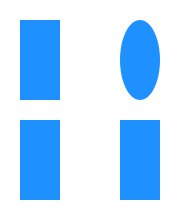

In [10]:
# Table.shape 对照演示：保持 table 语义，改变渲染形态
import importlib
import order_analyzer.features.schema as _s
import order_analyzer.features.entities as _e
import order_analyzer.features.analyzer as _m
importlib.reload(_s)
importlib.reload(_e)
importlib.reload(_m)
from order_analyzer import OrderAnalyzer
from order_analyzer.features.entities import Table

ideal_shape_table = [
    [Table(shape="rect", attr="A"), Table(shape="rect", attr="A")],
    [Table(shape="rect", attr="A"), Table(shape="rect", attr="A")],
]
actual_shape_table = [
    [Table(shape="rect", attr="A"), Table(shape="circle", attr="A")],
    [Table(shape="rect", attr="A"), Table(shape="rect", attr="A")],
]

shape_report = OrderAnalyzer(
    actual_matrix=actual_shape_table,
    ideal_matrix=ideal_shape_table,
    cell_size=(40, 80),
).report(features=("shapes",))

print("shape order:", shape_report["order"])
print("shape deviants:", shape_report["deviants"])
print("shape deviance_cells:", shape_report["deviance_cells"])
print("semantic role_counts:", shape_report["semantic"]["role_counts"])

shape_view = OrderAnalyzer(actual_matrix=actual_shape_table, ideal_matrix=ideal_shape_table, cell_size=(40, 80))
shape_view._prepare()
shape_view._stim.Show()

absolute-size order: 1.0
absolute-size deviants: 0


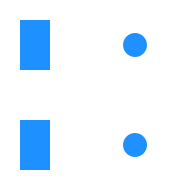

In [11]:
# 绝对尺寸演示：元素尺寸独立于网格比例（circle 保持正圆）
import importlib
import order_analyzer.features.schema as _s
import order_analyzer.features.entities as _e
import order_analyzer.features.analyzer as _m
importlib.reload(_s)
importlib.reload(_e)
importlib.reload(_m)
from order_analyzer import OrderAnalyzer
from order_analyzer.features.entities import Table

# 非方形 cell_size：40x80
# - rect 用绝对尺寸 (30, 50)
# - circle 用绝对尺寸 24（等价于 24x24）
ideal_abs = [
    [Table(shape="rect", size=(30, 50), attr="A"), Table(shape="circle", size=24, attr="A")],
    [Table(shape="rect", size=(30, 50), attr="A"), Table(shape="circle", size=24, attr="A")],
]
actual_abs = [
    [Table(shape="rect", size=(30, 50), attr="A"), Table(shape="circle", size=24, attr="A")],
    [Table(shape="rect", size=(30, 50), attr="A"), Table(shape="circle", size=24, attr="A")],
]

abs_report = OrderAnalyzer(
    actual_matrix=actual_abs,
    ideal_matrix=ideal_abs,
    cell_size=(40, 80),
).report(features=("shapes",))

print("absolute-size order:", abs_report["order"])
print("absolute-size deviants:", abs_report["deviants"])

abs_view = OrderAnalyzer(actual_matrix=actual_abs, ideal_matrix=ideal_abs, cell_size=(40, 80))
abs_view._prepare()
abs_view._stim.Show()

layout spacing (scaled): [19, 30]
layout size (scaled): [90.0, 56.0]
order: 0.7778
deviants: 2
deviance_by_feature: {'shapes': {'count': 1, 'ratio': 0.1111}, 'custom_attr': {'count': 1, 'ratio': 0.1111}, 'positions': {'count': 1, 'ratio': 0.1111}}
deviance_cells: [{'row': 0, 'col': 1}, {'row': 0, 'col': 2}]


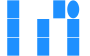

In [4]:
# 固定网格系统演示：密集网格 + 1:2 右偏 + 1:3 双桌语义（方+圆）
import importlib
import order_analyzer.features.schema as _s
import order_analyzer.features.entities as _e
import order_analyzer.features.analyzer as _m
importlib.reload(_s)
importlib.reload(_e)
importlib.reload(_m)
from order_analyzer.features.analyzer import OrderAnalyzer
from order_analyzer.features.entities import Table

# 画布缩小一点形成“相对密集”视觉
LAYOUT_MM = (900, 560)
SCALE = 0.1

def ideal_row():
    return [
        Table(shape="rect", size=(120, 180), attr="A"),
        Table(shape="rect", size=(120, 180), attr="A"),
        Table(shape="rect", size=(120, 180), attr="A"),
    ]

ideal_layout = [ideal_row(), ideal_row(), ideal_row()]

# actual:
# 1) 网格更密集（由更小 layout_size 控制）
# 2) 1:2 (row=1,col=2 -> 0-based [0][1]) 向右偏移
# 3) 1:3 (0-based [0][2]) 设为“方+圆双桌”语义：用 circle + 语义 attr 标注
actual_layout = [ideal_row(), ideal_row(), ideal_row()]
actual_layout[0][1] = {
    "shape": "rect",
    "size": (120, 180),
    "attr": "A",
    "x_offset": 16,
}
actual_layout[0][2] = {
    "shape": "circle",
    "size": 120,
    "attr": "double_table_rect_circle",
}

layout_analyzer = OrderAnalyzer(
    actual_matrix=actual_layout,
    ideal_matrix=ideal_layout,
    layout_size=LAYOUT_MM,
    fit_to_layout=True,
    unit_scale=SCALE,
 )

# 把位置偏移也纳入评分，确保“右偏”会拉低分数
layout_report = layout_analyzer.report(features=("shapes", "custom_attr", "positions"))

print("layout spacing (scaled):", layout_report["layout"]["spacing"])
print("layout size (scaled):", layout_report["layout"]["size"])
print("order:", layout_report["order"])

print("deviants:", layout_report["deviants"])

print("deviance_by_feature:", layout_report["deviance_by_feature"])

print("deviance_cells:", layout_report["deviance_cells"])


layout_analyzer._prepare()
layout_analyzer._stim.Show()